# Phase I – Human-only pair: How does AstroVision behave?

We test the AstroVision Advanced model (Zoobot, fine-tuned on Galaxy10 DECals) on galaxy images it has never seen.
We treat the model as a **black box**: we only look at the input image and the output (5 class probabilities).

**Before running:** the dataset must be in `data/Galaxy10_DECals.h5` and the model in `model/zoobot_finetuned.ckpt`
(both in the project folder, one level above this notebook). Run the cells from top to bottom.

## 1. Setup

### 1.1 Imports

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from PIL import Image
from sklearn.manifold import TSNE
from zoobot.pytorch.training import finetune

### 1.2 Settings

Paths are relative to this notebook (which is in the `phase1` folder).

In [2]:
DATA_PATH = '../data/Galaxy10_DECals.h5'
CHECKPOINT_PATH = '../model/zoobot_finetuned.ckpt'

os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)

VALIDATION_SHARE = 0.2
RANDOM_SEED = 42

In [ ]:
CLASS_NAMES = ['Spiral', 'Elliptical', 'Edge-on', 'Irregular', 'Merger']
ORIGINAL_NAMES = [
    'Disturbed', 'Merging', 'Round Smooth', 'In-between Smooth', 'Cigar Smooth',
    'Barred Spiral', 'Tight Spiral', 'Loose Spiral', 'Edge-on no Bulge', 'Edge-on with Bulge',
]
ORIGINAL_TO_NEW = [3, 4, 1, 1, 1, 0, 0, 0, 2, 2]
CLASS_COLORS = {'Spiral': '#1f77b4', 'Elliptical': '#ff7f0e', 'Edge-on': '#2ca02c', 'Irregular': '#9467bd', 'Merger': '#d62728',}
CORRECT_COLOR = '#9e9e9e'
WRONG_COLOR = '#d62728'

### 1.3 Rebuild the validation set

`train.py` shuffled all images with seed 42 and used the first 20% as validation set.
We repeat exactly this, so we only test on images the model was **not** trained on.

In [ ]:
data_file = h5py.File(DATA_PATH, 'r')
all_labels = data_file['ans'][:]
all_redshifts = data_file['redshift'][:]
number_of_images = len(all_labels)
random_generator = np.random.default_rng(RANDOM_SEED)
shuffled_indices = random_generator.permutation(number_of_images)
number_of_validation_images = int(number_of_images * VALIDATION_SHARE)
validation_indices = shuffled_indices[:number_of_validation_images]
training_indices = shuffled_indices[number_of_validation_images:]

print('All images:       ', number_of_images)
print('Training images:  ', len(training_indices))
print('Validation images:', len(validation_indices))

All images:        17736
Training images:   14189
Validation images: 3547


### 1.4 Load the validation images

Reading single images from the `.h5` file is very slow, because the file is compressed in blocks of 555 images.
So the first time, we read all images at once, keep only the validation images
and save them to `results/validation_images.npy`. Later runs load this file instead.

In [5]:
CACHE_PATH = 'results/validation_images.npy'

if os.path.exists(CACHE_PATH):
    print('Loading the saved validation images ...')
    validation_images = np.load(CACHE_PATH)
else:
    print('Reading all images from the .h5 file ...')
    all_images = data_file['images'][:]
    validation_images = all_images[validation_indices]
    del all_images
    np.save(CACHE_PATH, validation_images)

print('Shape of the validation images:', validation_images.shape)

Loading the saved validation images ...


Shape of the validation images: (3547, 256, 256, 3)


### 1.5 Load the model

We use the Apple GPU (`mps`) or an NVIDIA GPU (`cuda`) if available, otherwise the CPU.

In [6]:
if torch.backends.mps.is_available():
    device = 'mps'
elif torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'
print('Device:', device)

model = finetune.FinetuneableZoobotClassifier.load_from_checkpoint(CHECKPOINT_PATH, map_location='cpu')
model = model.to(device)
model.eval()

print('Model loaded')

Device: mps


Model loaded


In [7]:
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

### 1.6 Run the model on all validation images

We give the model 64 images at a time. The model returns 5 raw scores per image,
and **softmax** turns them into 5 probabilities that add up to 1.

In [ ]:
BATCH_SIZE = 64
all_probabilities = []

for batch_start in range(0, len(validation_images), BATCH_SIZE):
    batch_images = validation_images[batch_start:batch_start + BATCH_SIZE]
    image_tensors = []
    for image in batch_images:
        image_tensors.append(image_transform(Image.fromarray(image)))
    batch = torch.stack(image_tensors).to(device)
    with torch.no_grad():
        scores = model(batch)
        probabilities = torch.softmax(scores, dim=1)
    for image_probabilities in probabilities.cpu().numpy():
        all_probabilities.append(image_probabilities)

print('Predicted', len(all_probabilities), 'images')

Predicted 3547 images


### 1.7 Image factors

Besides the model output, we measure 4 simple properties ("factors") of every image,
to check later whether they influence the results:

| Factor | How we compute it |
|---|---|
| `redshift` | stored in the dataset: how far away the galaxy is (bigger = farther) |
| `size` | fraction of pixels brighter than 60 of 255 (the dark sky is about 35) |
| `center_brightness` | mean brightness of the 32 x 32 pixels in the middle |
| `redness` | mean of the red channel minus mean of the blue channel |

In [ ]:
def compute_image_factors(image):
    image = image.astype(float)
    grey_image = image.mean(axis=2)
    bright_pixels = grey_image > 60
    size = bright_pixels.mean()
    center = grey_image[112:144, 112:144]
    center_brightness = center.mean()
    red_mean = image[:, :, 0].mean()
    blue_mean = image[:, :, 2].mean()
    redness = red_mean - blue_mean

    return size, center_brightness, redness

### 1.8 Results table

One row per validation image. We also save it to `results/predictions.csv`.

In [ ]:
rows = []

for position in range(len(validation_indices)):
    image_index = validation_indices[position]
    probabilities = all_probabilities[position]
    original_label = int(all_labels[image_index])
    true_label = ORIGINAL_TO_NEW[original_label]
    predicted_label = int(np.argmax(probabilities))
    size, center_brightness, redness = compute_image_factors(validation_images[position])
    row = {
        'position': position,
        'image_index': int(image_index),
        'original_class': ORIGINAL_NAMES[original_label],
        'true_class': CLASS_NAMES[true_label],
        'predicted_class': CLASS_NAMES[predicted_label],
        'correct': predicted_label == true_label,
        'confidence': float(probabilities[predicted_label]),
        'prob_Spiral': float(probabilities[0]),
        'prob_Elliptical': float(probabilities[1]),
        'prob_Edge-on': float(probabilities[2]),
        'prob_Irregular': float(probabilities[3]),
        'prob_Merger': float(probabilities[4]),
        'redshift': float(all_redshifts[image_index]),
        'size': size,
        'center_brightness': center_brightness,
        'redness': redness,
    }
    rows.append(row)
table = pd.DataFrame(rows)
table.to_csv('results/predictions.csv', index=False)
accuracy = table['correct'].mean() * 100
print('Accuracy on the validation set:', round(accuracy, 1), '%')

Accuracy on the validation set: 92.9 %


## 2. Behaviour per class

### 2.1 Training images per class and accuracy per class

In [ ]:
training_counts = []
accuracy_per_class = []

for class_number in range(5):
    count = 0
    for image_index in training_indices:
        if ORIGINAL_TO_NEW[all_labels[image_index]] == class_number:
            count = count + 1
    training_counts.append(count)
    class_rows = table[table['true_class'] == CLASS_NAMES[class_number]]
    accuracy_per_class.append(class_rows['correct'].mean() * 100)

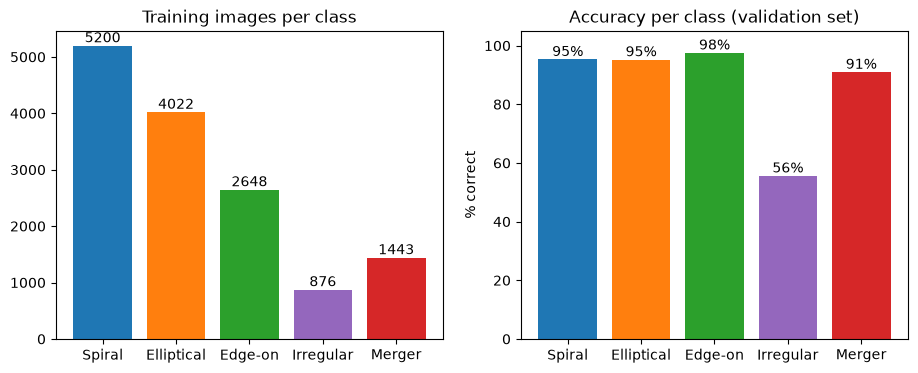

In [ ]:
bar_colors = []

for class_name in CLASS_NAMES:
    bar_colors.append(CLASS_COLORS[class_name])
figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(11, 4))
left_axis.bar(CLASS_NAMES, training_counts, color=bar_colors)
left_axis.set_title('Training images per class')
for class_number in range(5):
    count = training_counts[class_number]
    left_axis.text(class_number, count, str(count), ha='center', va='bottom')
right_axis.bar(CLASS_NAMES, accuracy_per_class, color=bar_colors)
right_axis.set_title('Accuracy per class (validation set)')
right_axis.set_ylabel('% correct')
right_axis.set_ylim(0, 105)
for class_number in range(5):
    value = accuracy_per_class[class_number]
    right_axis.text(class_number, value, str(round(value)) + '%', ha='center', va='bottom')

plt.savefig('figures/fig1_class_counts_and_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.2 Confusion matrix

Each row is a true class, each column a predicted class.
The colour shows the percentage of the row, the number in brackets is the number of images.

In [ ]:
confusion_counts = np.zeros((5, 5), dtype=int)
for row_number in range(len(table)):
    true_number = CLASS_NAMES.index(table['true_class'][row_number])
    predicted_number = CLASS_NAMES.index(table['predicted_class'][row_number])
    confusion_counts[true_number, predicted_number] = confusion_counts[true_number, predicted_number] + 1
confusion_percent = np.zeros((5, 5))
for true_number in range(5):
    row_total = confusion_counts[true_number].sum()
    confusion_percent[true_number] = confusion_counts[true_number] / row_total * 100

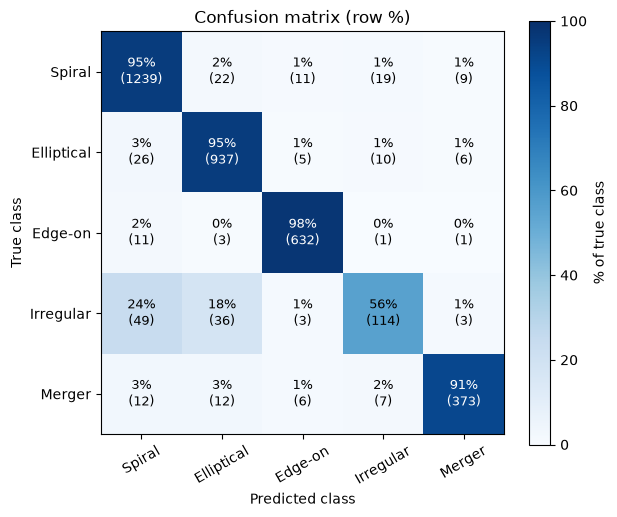

In [ ]:
figure, axis = plt.subplots(figsize=(6.5, 5.5))
image = axis.imshow(confusion_percent, cmap='Blues', vmin=0, vmax=100)
for true_number in range(5):
    for predicted_number in range(5):
        percent = confusion_percent[true_number, predicted_number]
        count = confusion_counts[true_number, predicted_number]
        if percent > 60:
            text_color = 'white'
        else:
            text_color = 'black'
        axis.text(predicted_number, true_number, f'{percent:.0f}%\n({count})',
                  ha='center', va='center', color=text_color, fontsize=9)
        
axis.set_xticks(range(5), CLASS_NAMES, rotation=30)
axis.set_yticks(range(5), CLASS_NAMES)
axis.set_xlabel('Predicted class')
axis.set_ylabel('True class')
axis.set_title('Confusion matrix (row %)')
figure.colorbar(image, label='% of true class')

plt.savefig('figures/fig2_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Original subtypes vs. predicted class

The same idea as the confusion matrix, but the rows are the 10 **original** Galaxy10 classes.
This shows which subtype inside a merged class causes the errors.

In [ ]:
subtype_counts = np.zeros((10, 5), dtype=int)
for row_number in range(len(table)):
    original_number = ORIGINAL_NAMES.index(table['original_class'][row_number])
    predicted_number = CLASS_NAMES.index(table['predicted_class'][row_number])
    subtype_counts[original_number, predicted_number] = subtype_counts[original_number, predicted_number] + 1
subtype_percent = np.zeros((10, 5))
for original_number in range(10):
    row_total = subtype_counts[original_number].sum()
    subtype_percent[original_number] = subtype_counts[original_number] / row_total * 100

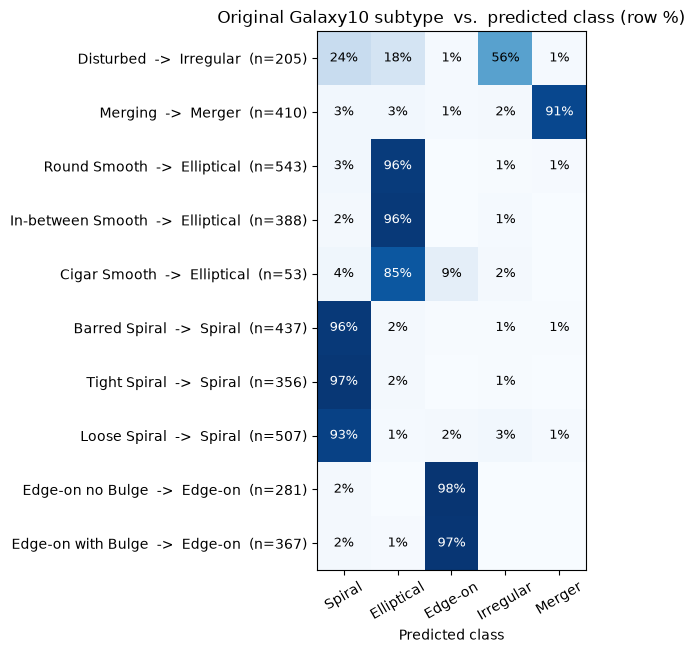

In [ ]:
row_labels = []
for original_number in range(10):
    merged_class = CLASS_NAMES[ORIGINAL_TO_NEW[original_number]]
    number_of_rows = subtype_counts[original_number].sum()
    row_labels.append(f'{ORIGINAL_NAMES[original_number]}  ->  {merged_class}  (n={number_of_rows})')

figure, axis = plt.subplots(figsize=(8, 7))
axis.imshow(subtype_percent, cmap='Blues', vmin=0, vmax=100)
for original_number in range(10):
    for predicted_number in range(5):
        percent = subtype_percent[original_number, predicted_number]
        if percent >= 0.5:
            if percent > 60:
                text_color = 'white'
            else:
                text_color = 'black'
            axis.text(predicted_number, original_number, f'{percent:.0f}%',
                      ha='center', va='center', color=text_color, fontsize=9)

axis.set_xticks(range(5), CLASS_NAMES, rotation=30)
axis.set_yticks(range(10), row_labels)
axis.set_xlabel('Predicted class')
axis.set_title('Original Galaxy10 subtype  vs.  predicted class (row %)')

plt.savefig('figures/fig3_subtypes_vs_prediction.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.4 Most common mistakes

In [ ]:
wrong = table[table['correct'] == False].copy()
wrong['mistake'] = wrong['true_class'] + ' -> ' + wrong['predicted_class']
print('Number of wrong predictions:', len(wrong))
print()
print('Most common mistakes (true -> predicted):')
print(wrong['mistake'].value_counts().head(8))

Number of wrong predictions: 252

Most common mistakes (true -> predicted):
mistake
Irregular -> Spiral        49
Irregular -> Elliptical    36
Elliptical -> Spiral       26
Spiral -> Elliptical       22
Spiral -> Irregular        19
Merger -> Spiral           12
Merger -> Elliptical       12
Spiral -> Edge-on          11
Name: count, dtype: int64


## 3. Confidence of correct vs. wrong predictions

The confidence is the probability of the predicted class (between 0.2 and 1.0).
The histograms show one panel per true class. `density=True` scales both histograms to the same area,
so we can compare their shapes even though there are many more correct than wrong predictions.

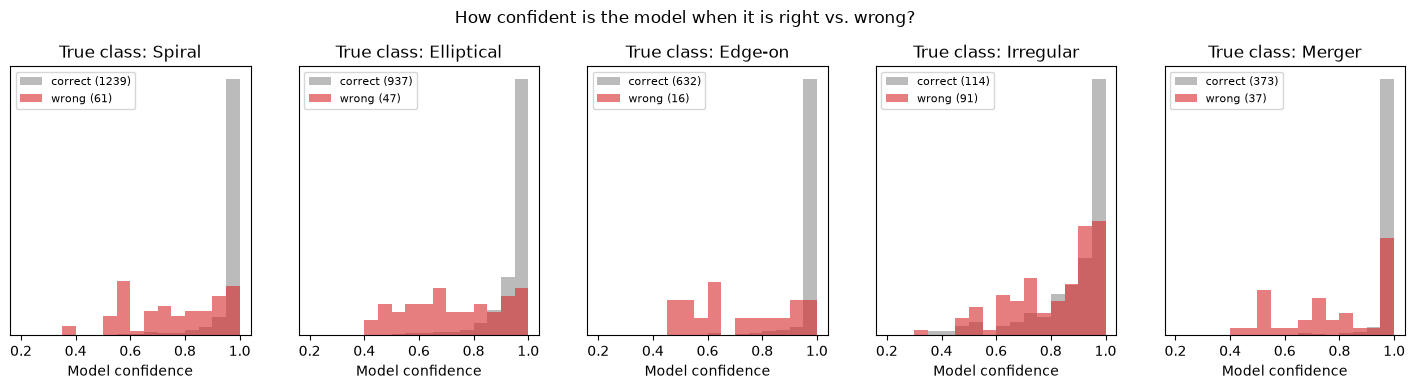

In [ ]:
figure, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharex=True)
bin_edges = np.linspace(0.2, 1.0, 17)
for class_number in range(5):
    class_name = CLASS_NAMES[class_number]
    axis = axes[class_number]
    class_rows = table[table['true_class'] == class_name]
    correct_confidence = class_rows[class_rows['correct'] == True]['confidence']
    wrong_confidence = class_rows[class_rows['correct'] == False]['confidence']
    axis.hist(correct_confidence, bins=bin_edges, color=CORRECT_COLOR, alpha=0.7, density=True,
              label=f'correct ({len(correct_confidence)})')
    axis.hist(wrong_confidence, bins=bin_edges, color=WRONG_COLOR, alpha=0.6, density=True,
              label=f'wrong ({len(wrong_confidence)})')
    axis.set_title(f'True class: {class_name}')
    axis.set_xlabel('Model confidence')
    axis.set_yticks([])
    axis.legend(fontsize=8, loc='upper left')

figure.suptitle('How confident is the model when it is right vs. wrong?', y=1.04)
plt.savefig('figures/fig4_confidence_correct_vs_wrong.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Image factors

### 4.1 Split every factor into 5 equally-sized groups

`pd.qcut` sorts the images by a factor and cuts them into 5 groups with the same number of images
(quintiles). Images without a redshift value get no group.

In [ ]:
FACTORS = ['redshift', 'size', 'center_brightness', 'redness']
FACTOR_LABELS = [
    'Redshift (distance)  ->  farther',
    'Galaxy size (fraction of bright pixels)',
    'Brightness of the image center',
    'Redness (red minus blue)',
]
GROUP_NAMES = ['very low', 'low', 'mid', 'high', 'very high']
for factor in FACTORS:
    table[factor + '_group'] = pd.qcut(table[factor], q=5, labels=GROUP_NAMES)

In [20]:
def accuracy_per_group(rows, group_column):
    accuracies = []
    for group_name in GROUP_NAMES:
        rows_in_group = rows[rows[group_column] == group_name]
        accuracies.append(rows_in_group['correct'].mean() * 100)
    return accuracies

### 4.2 Accuracy depending on the image factors

One line per true class; the thick black line is all classes together.

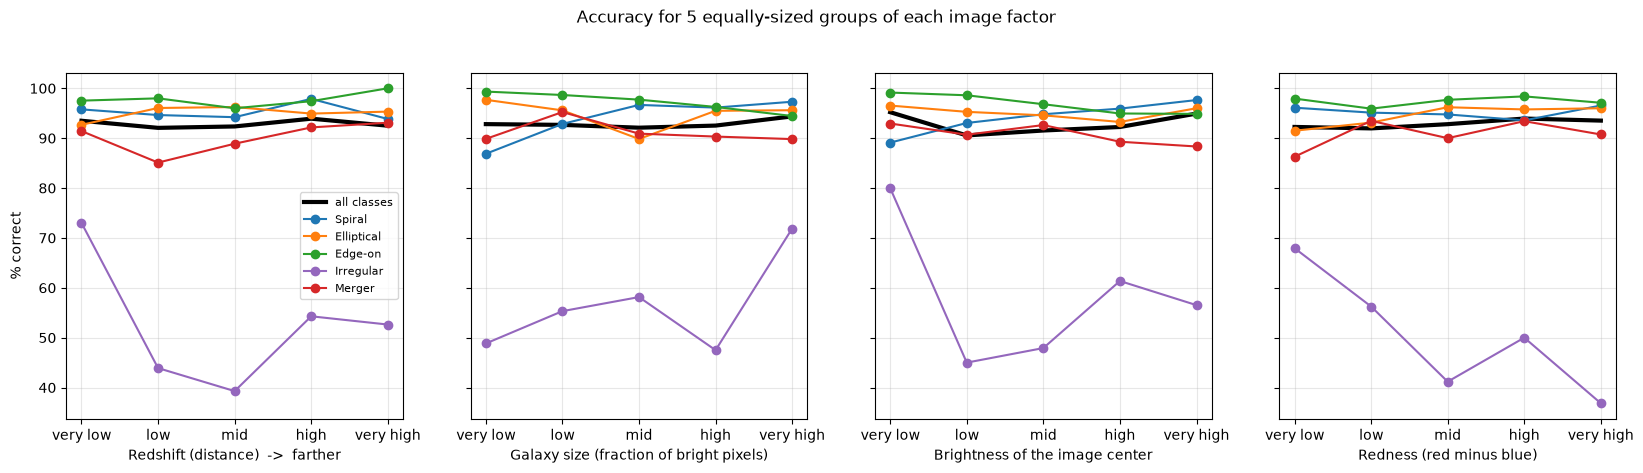

In [ ]:
figure, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)

for factor_number in range(4):
    axis = axes[factor_number]
    group_column = FACTORS[factor_number] + '_group'
    overall = accuracy_per_group(table, group_column)
    axis.plot(GROUP_NAMES, overall, color='black', linewidth=3, label='all classes')
    for class_name in CLASS_NAMES:
        class_rows = table[table['true_class'] == class_name]
        class_accuracies = accuracy_per_group(class_rows, group_column)
        axis.plot(GROUP_NAMES, class_accuracies, marker='o', color=CLASS_COLORS[class_name], label=class_name)
    axis.set_xlabel(FACTOR_LABELS[factor_number])
    axis.grid(alpha=0.3)

axes[0].set_ylabel('% correct')
axes[0].legend(fontsize=8)
figure.suptitle('Accuracy for 5 equally-sized groups of each image factor', y=1.02)
plt.savefig('figures/fig5_accuracy_vs_factors.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Looking at the images

Every caption shows the original class, the prediction with its confidence, and the redshift `z`.
Red captions are wrong predictions.

In [22]:
# Image grids are shown as JPEG inside the notebook to keep the file small. The saved files stay PNG.
%config InlineBackend.figure_formats = ['jpeg']

In [ ]:
def show_image_grid(rows, title, file_name, columns=8):
    number_of_grid_rows = int(np.ceil(len(rows) / columns))
    figure, axes = plt.subplots(number_of_grid_rows, columns, figsize=(columns * 2, number_of_grid_rows * 2.9))
    axes = np.array(axes).reshape(-1)
    for axis in axes:
        axis.axis('off')

    grid_position = 0
    for _, row in rows.iterrows():
        axis = axes[grid_position]
        axis.imshow(validation_images[int(row['position'])])
        caption = f'true: {row["original_class"]}\n'
        caption = caption + f'pred: {row["predicted_class"]} ({row["confidence"]:.0%})\n'
        caption = caption + f'z={row["redshift"]:.3f}'
        if row['correct']:
            axis.set_title(caption, fontsize=7, color='black')
        else:
            axis.set_title(caption, fontsize=7, color='red')

        grid_position = grid_position + 1

    figure.suptitle(title, fontsize=12)
    figure.tight_layout()
    plt.savefig('figures/' + file_name + '.png', dpi=120, bbox_inches='tight')
    plt.show()

### 5.1 The 24 mistakes the model was most confident about

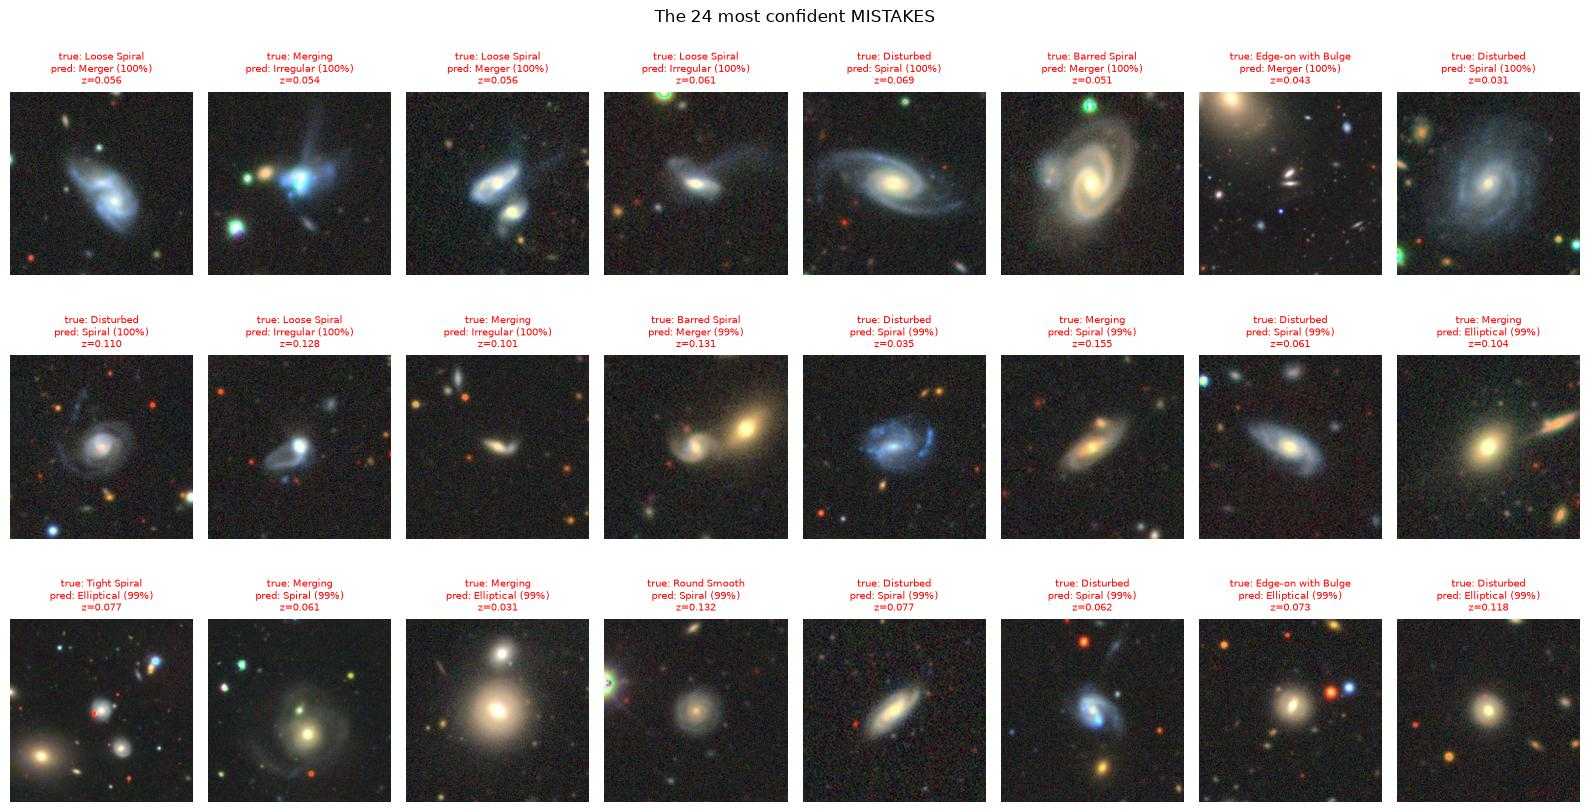

In [24]:
most_confident_mistakes = wrong.sort_values('confidence', ascending=False).head(24)
show_image_grid(most_confident_mistakes, 'The 24 most confident MISTAKES', 'examples_most_confident_mistakes')

### 5.2 The 4 most common mistakes (16 random examples each)

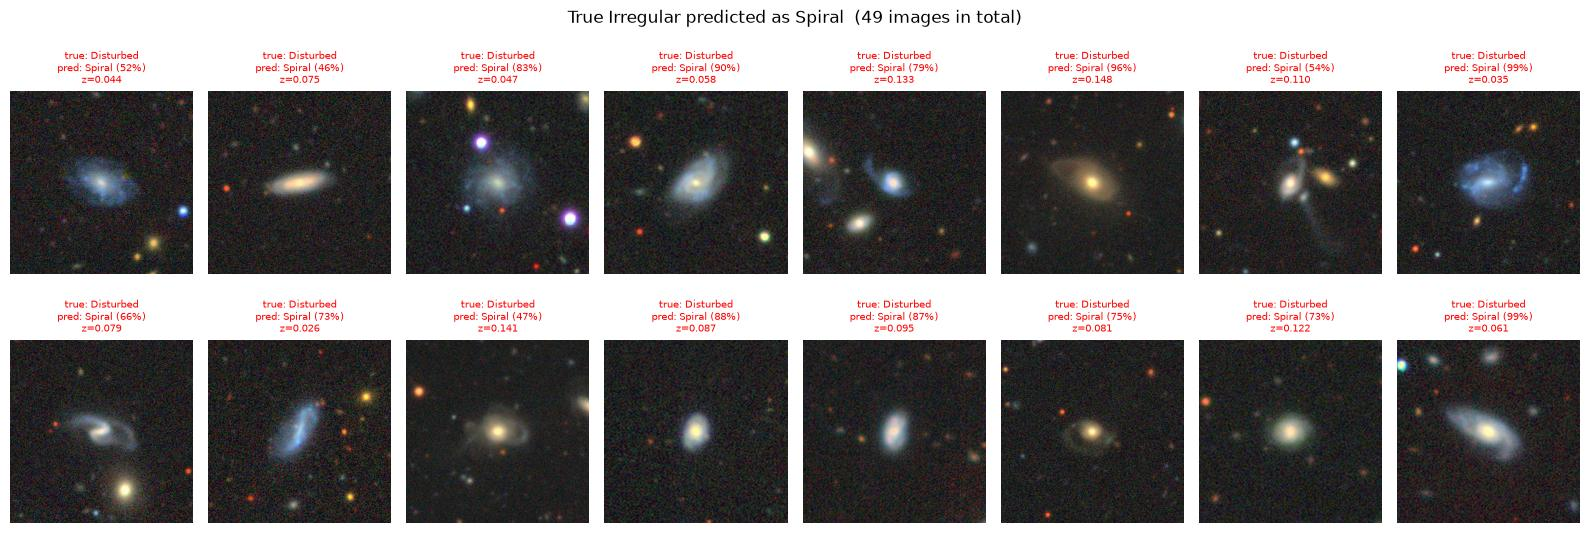

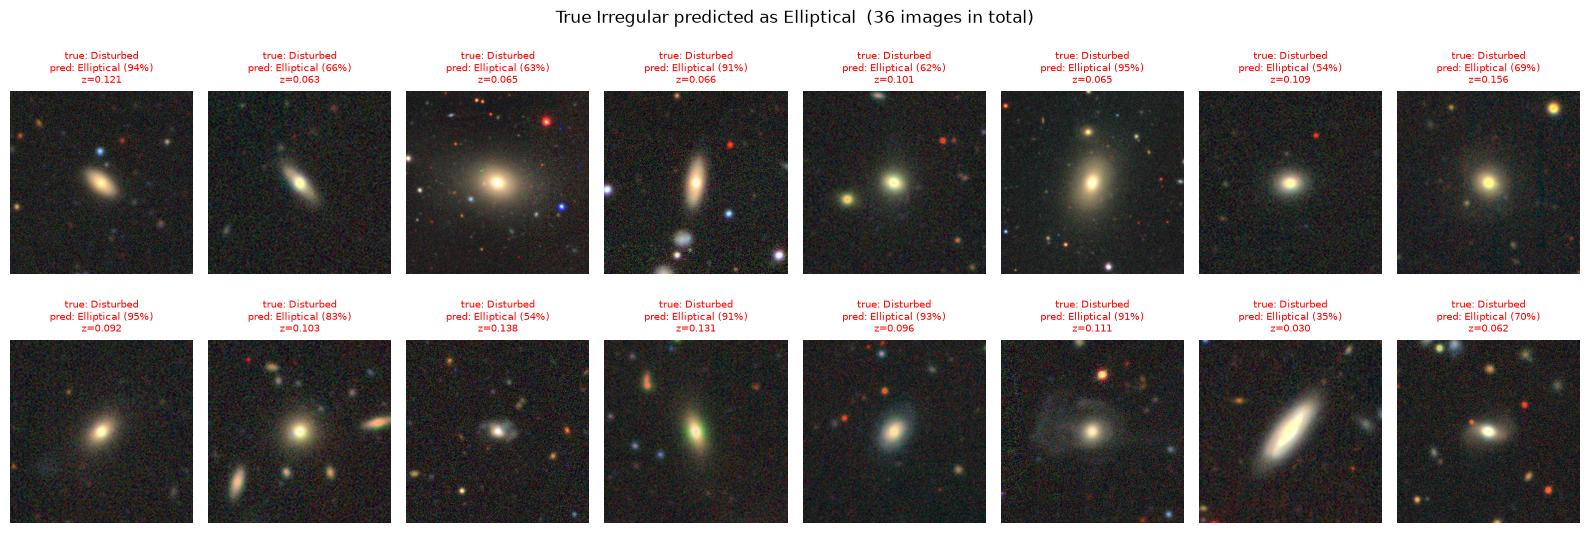

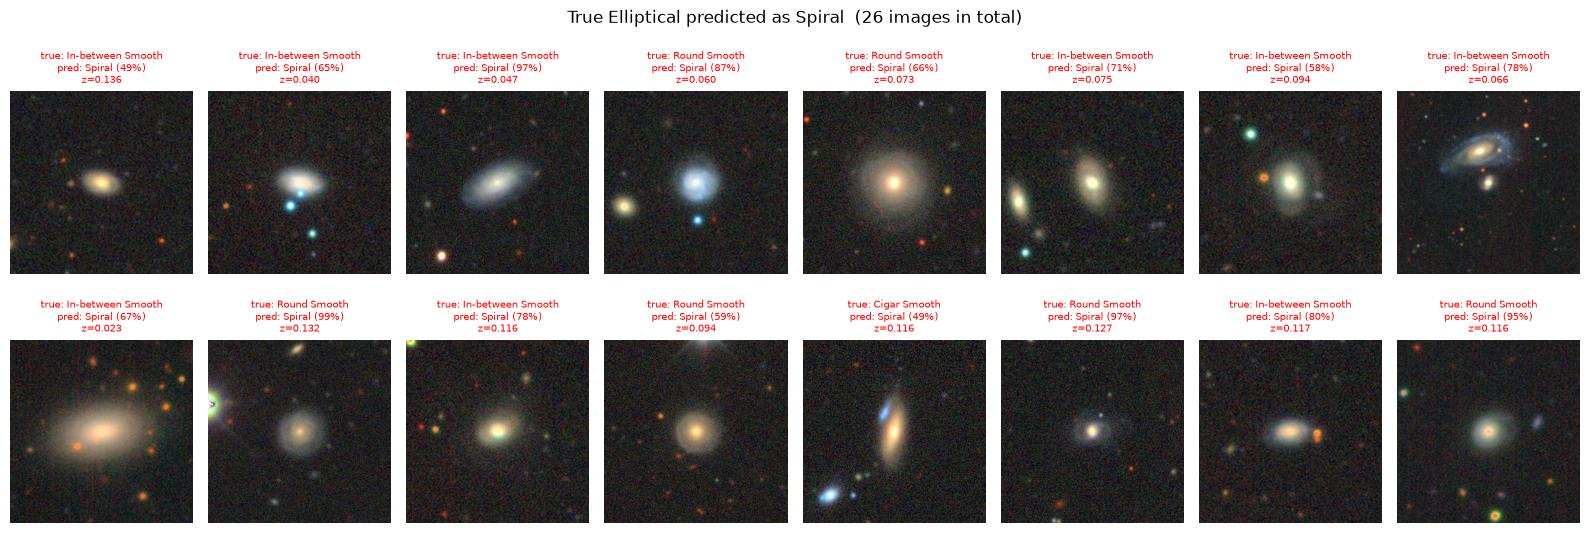

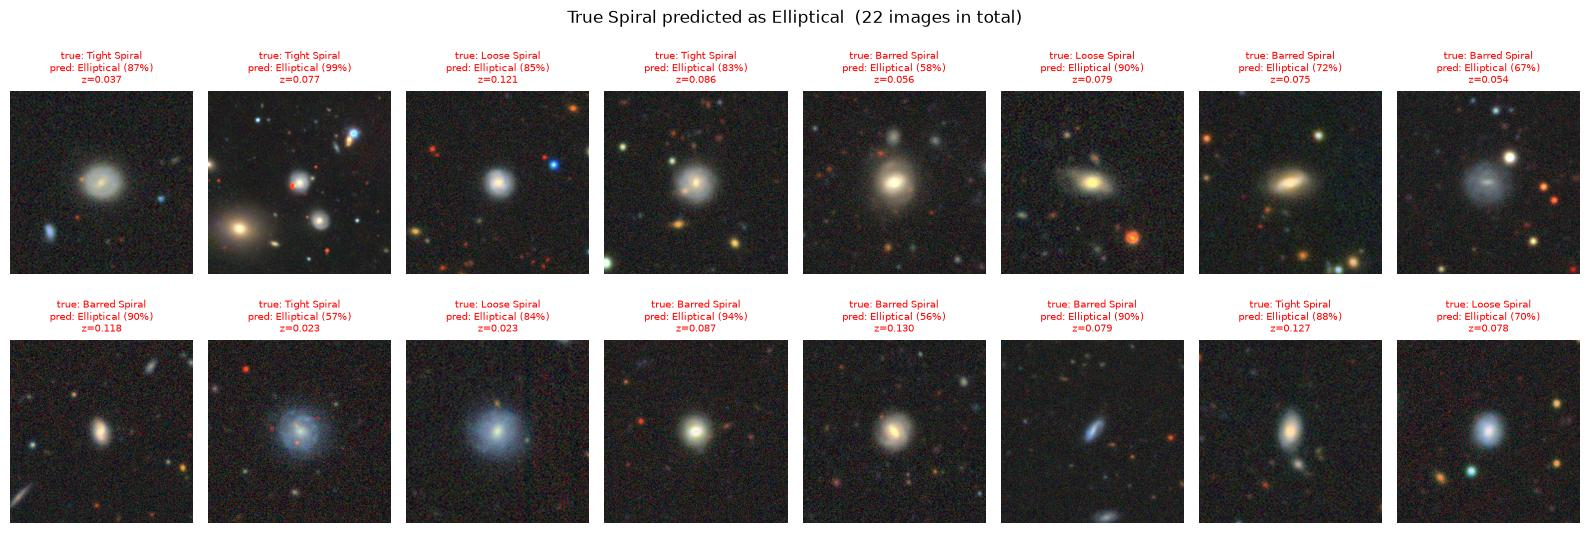

In [ ]:
top_mistakes = wrong['mistake'].value_counts().head(4)
for mistake_name in top_mistakes.index:
    rows_of_mistake = wrong[wrong['mistake'] == mistake_name]
    examples = rows_of_mistake.sample(min(16, len(rows_of_mistake)), random_state=0)
    true_class = examples['true_class'].iloc[0]
    predicted_class = examples['predicted_class'].iloc[0]
    title = f'True {true_class} predicted as {predicted_class}  ({len(rows_of_mistake)} images in total)'
    show_image_grid(examples, title, f'examples_{true_class}_as_{predicted_class}')

### 5.3 Correct vs. wrong for each class

Top row: 8 random correct predictions. Bottom row: 8 random wrong predictions of the same true class.

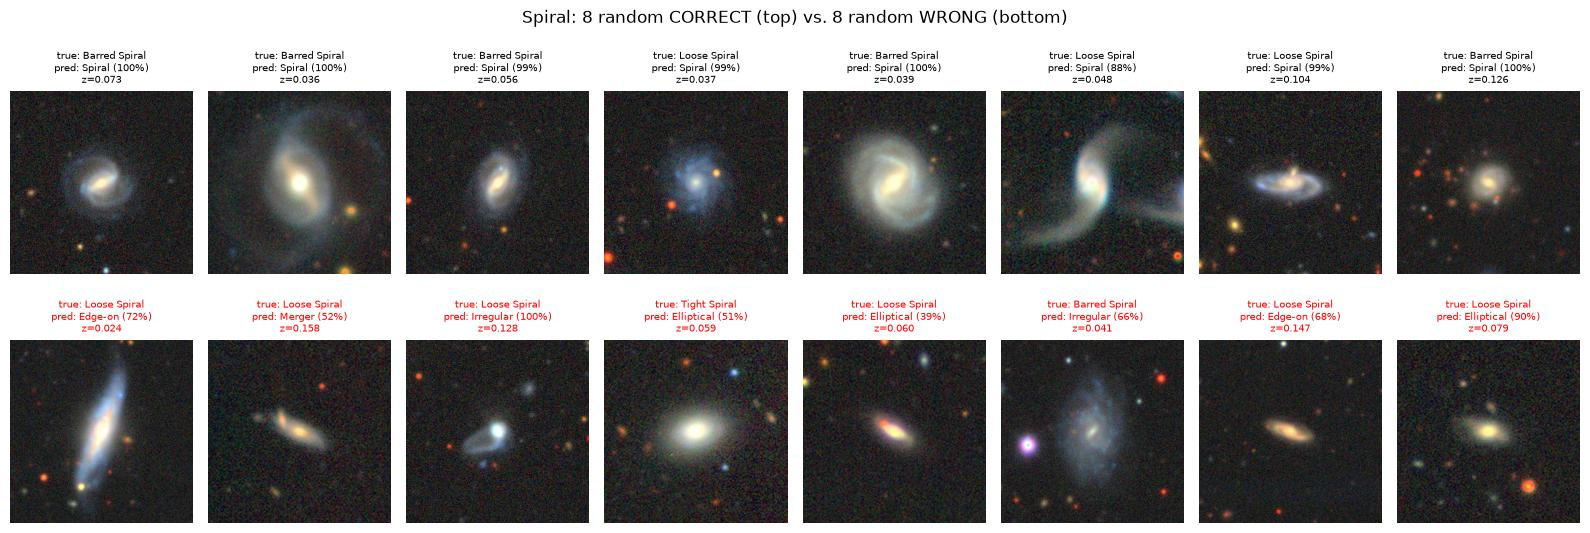

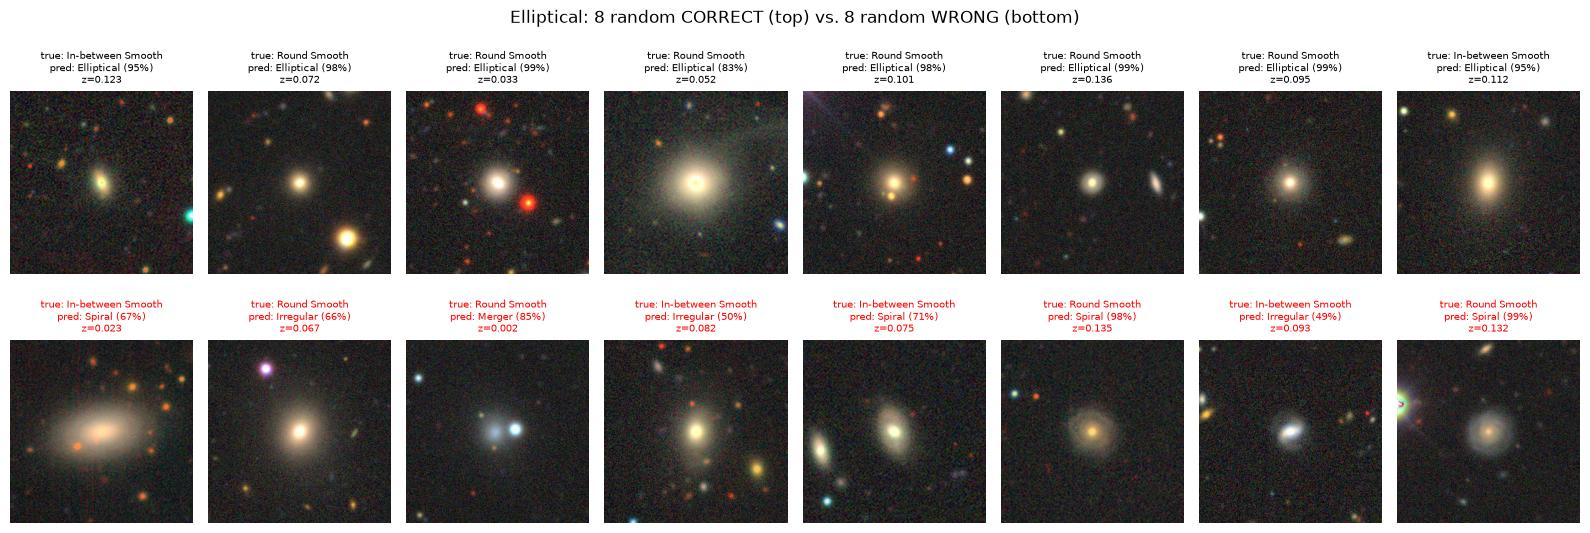

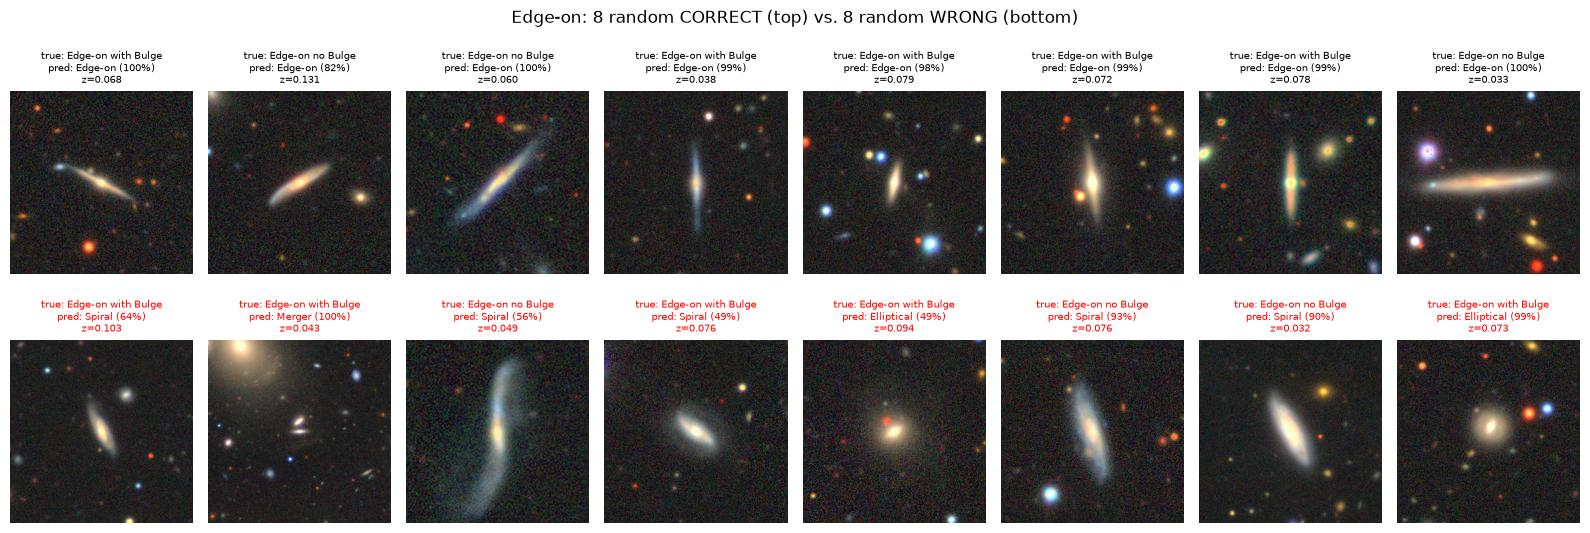

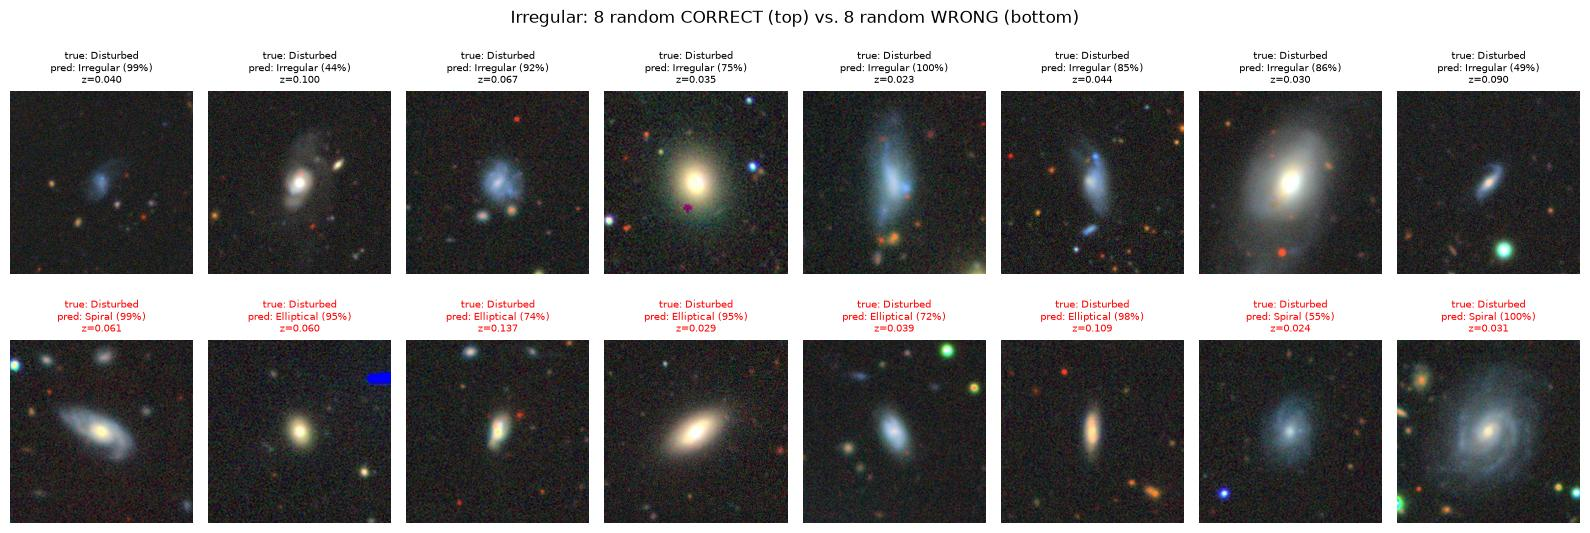

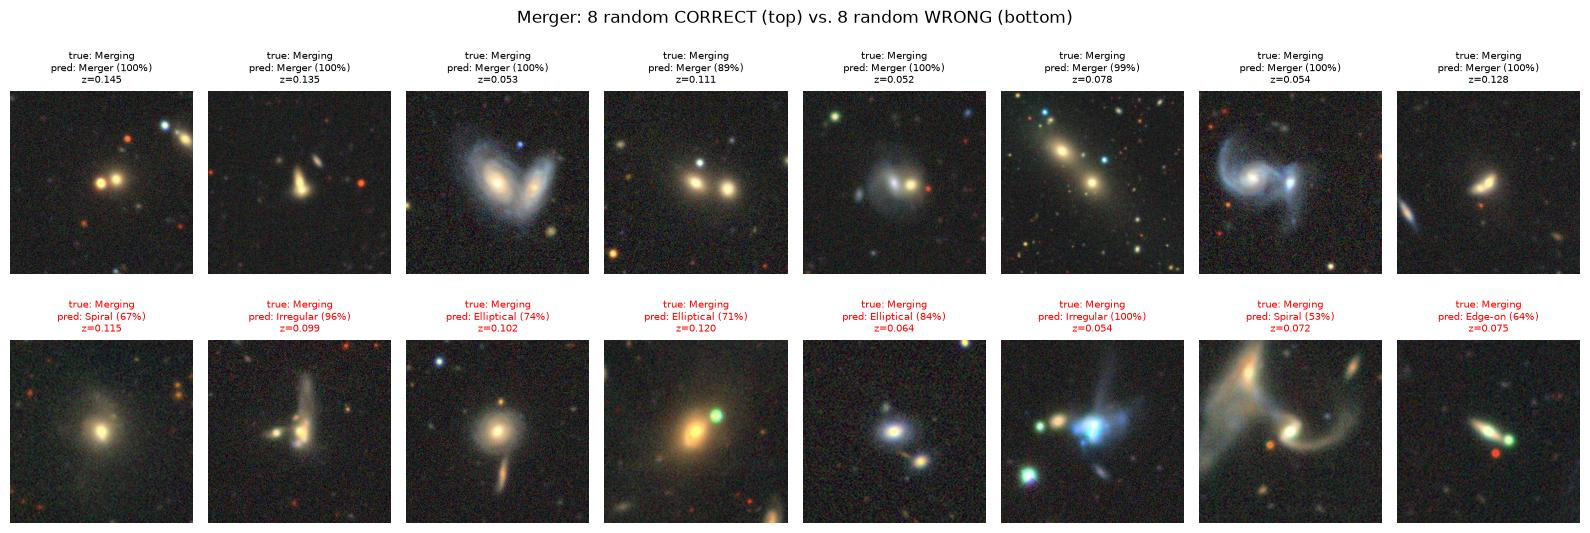

In [ ]:
for class_name in CLASS_NAMES:
    class_rows = table[table['true_class'] == class_name]
    correct_rows = class_rows[class_rows['correct'] == True]
    wrong_rows = class_rows[class_rows['correct'] == False]
    correct_examples = correct_rows.sample(min(8, len(correct_rows)), random_state=0)
    wrong_examples = wrong_rows.sample(min(8, len(wrong_rows)), random_state=0)
    examples = pd.concat([correct_examples, wrong_examples])
    title = f'{class_name}: 8 random CORRECT (top) vs. 8 random WRONG (bottom)'
    show_image_grid(examples, title, f'examples_correct_vs_wrong_{class_name}')

## 6. Going deeper

This section looks more closely at the patterns from sections 2-5, mainly at the Irregular class
(true class Irregular = original subtype "Disturbed").

### 6.1 Is it the model or the label?

The labels of Galaxy10 come from Galaxy Zoo volunteers. Maybe some "Disturbed" galaxies don't look disturbed at all.
To check this, every wrongly predicted Irregular image is labeled by eye, **without seeing the model's prediction**:
`d` = looks disturbed (tidal tails, a close interacting neighbour, an asymmetric plume or a clumpy irregular shape),
`n` = looks like a normal spiral, elliptical or edge-on galaxy.

The labels are stored in `results/irregular_labels.csv` (one row per image, the ID is shown in the grid below).
They were made by Claude (AI) and then checked by us, see `ai-interactions/`.

In [ ]:
wrong_irregular = table[(table['true_class'] == 'Irregular') & (table['correct'] == False)]
wrong_irregular = wrong_irregular.reset_index(drop=True)
print('Wrongly predicted Irregular images:', len(wrong_irregular))
LABELS_PATH = 'results/irregular_labels.csv'
if os.path.exists(LABELS_PATH):
    print('The label file already exists:', LABELS_PATH)
else:
    empty_labels = pd.DataFrame()
    empty_labels['id'] = range(len(wrong_irregular))
    empty_labels['image_index'] = wrong_irregular['image_index']
    empty_labels['label'] = ''
    empty_labels.to_csv(LABELS_PATH, index=False)
    print('Created the empty label file:', LABELS_PATH)

Wrongly predicted Irregular images: 91
The label file already exists: results/irregular_labels.csv


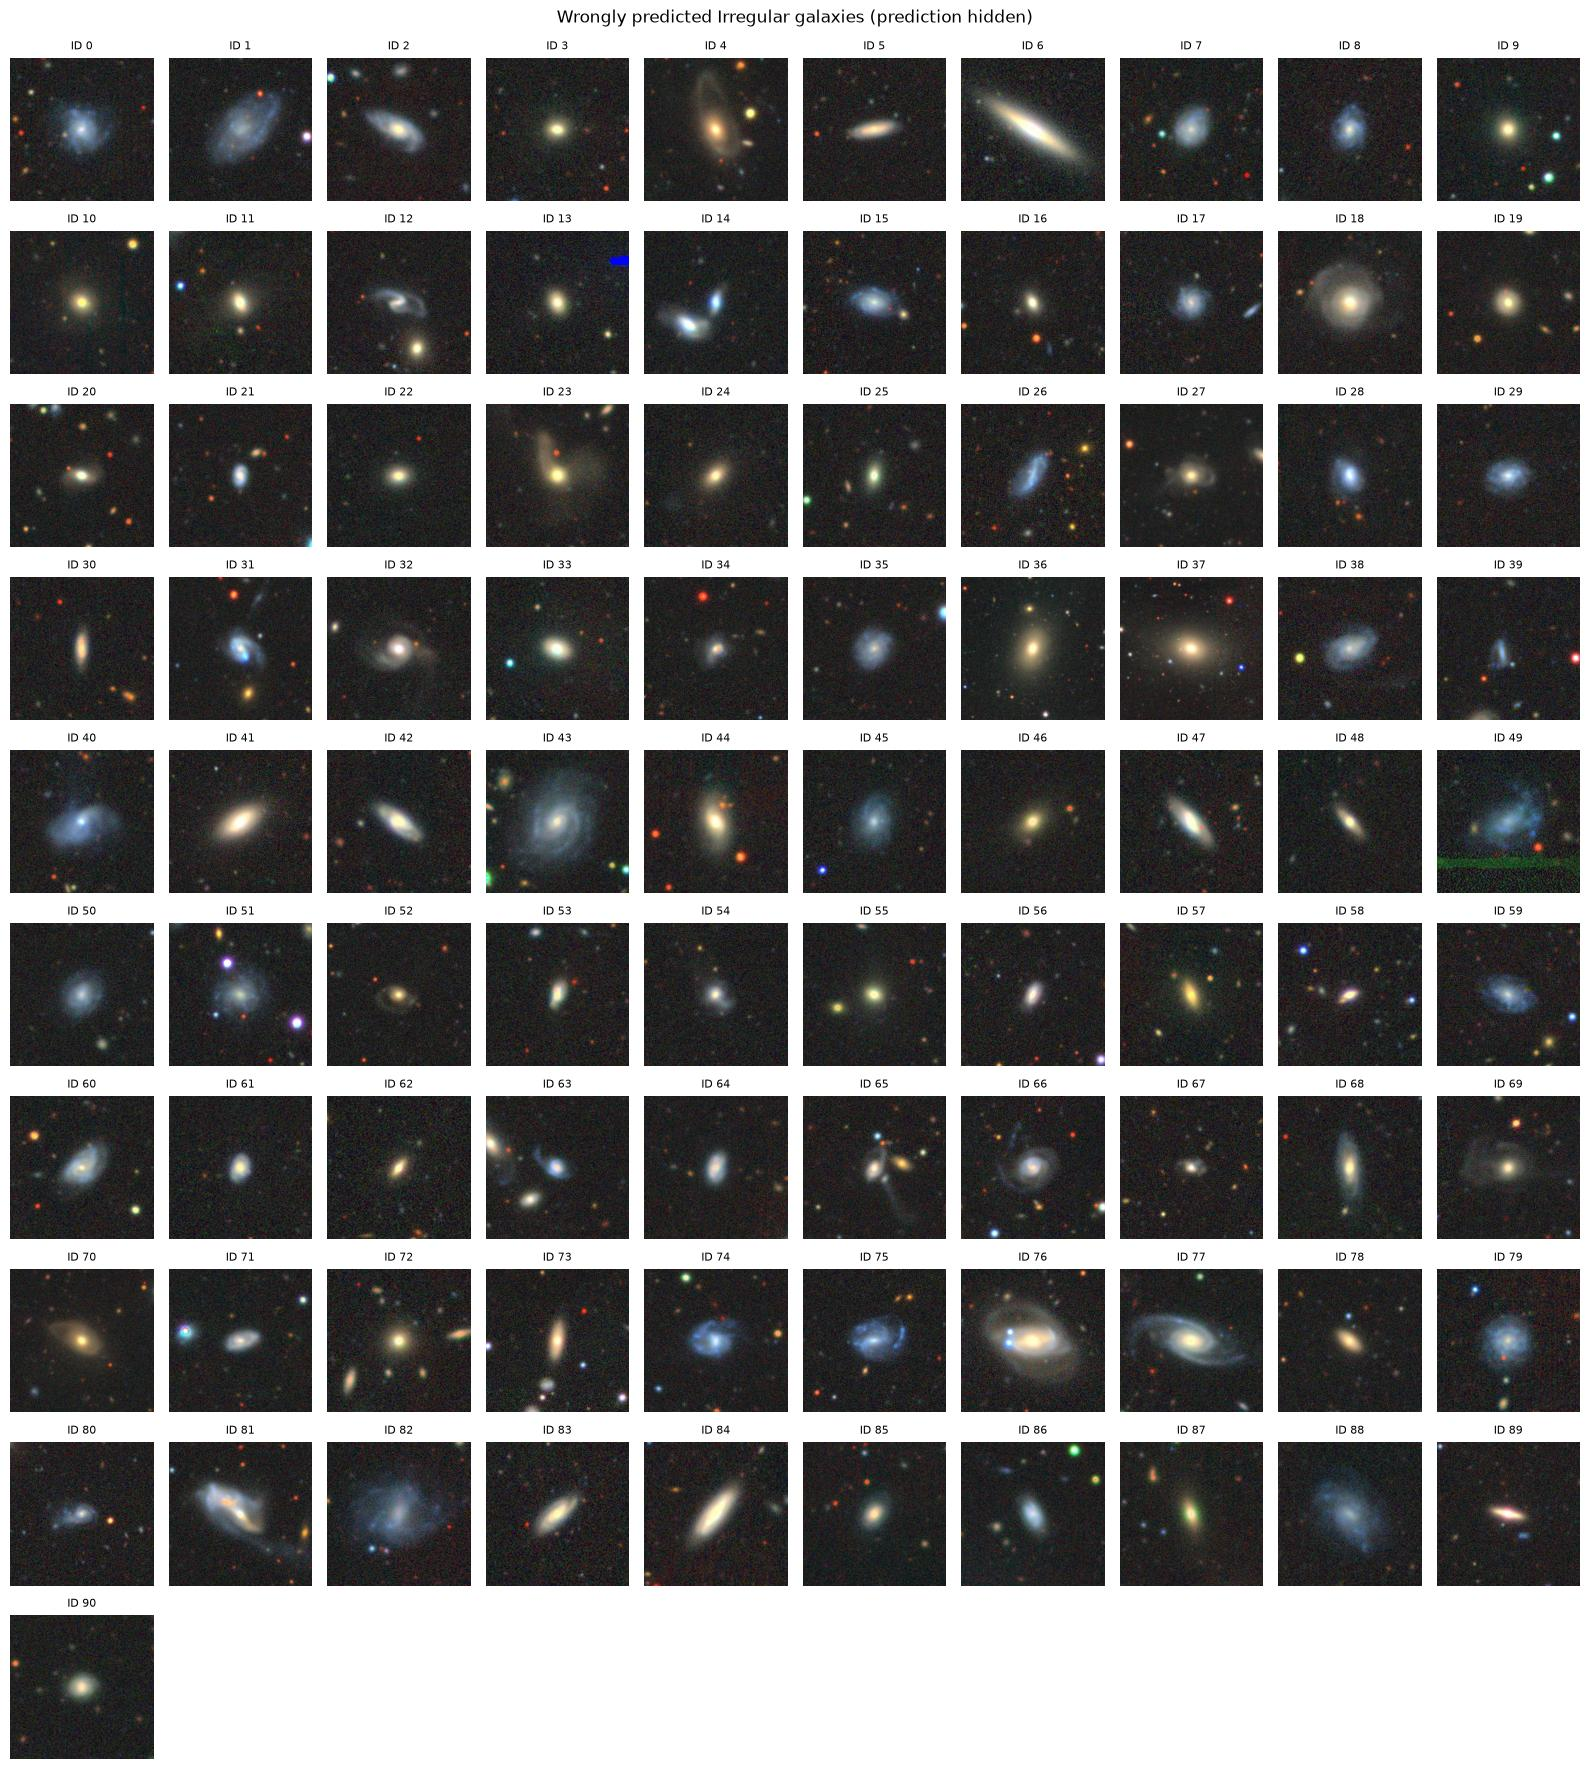

In [ ]:
columns = 10
number_of_grid_rows = int(np.ceil(len(wrong_irregular) / columns))
figure, axes = plt.subplots(number_of_grid_rows, columns, figsize=(columns * 1.6, number_of_grid_rows * 1.75))
axes = np.array(axes).reshape(-1)
for axis in axes:
    axis.axis('off')
for row_number in range(len(wrong_irregular)):
    position = int(wrong_irregular['position'][row_number])
    axes[row_number].imshow(validation_images[position])
    axes[row_number].set_title('ID ' + str(row_number), fontsize=8)
figure.tight_layout()
figure.suptitle('Wrongly predicted Irregular galaxies (prediction hidden)', y=1.01)
plt.savefig('figures/labeling_grid_irregular.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
label_table = pd.read_csv(LABELS_PATH, dtype=str)
label_table = label_table.fillna('')
verdicts = []
for row_number in range(len(label_table)):
    label = label_table['label'][row_number].strip().lower()

    if label == 'd':
        verdicts.append('looks disturbed')
    elif label == 'n':
        verdicts.append('looks normal')
    else:
        verdicts.append('not labeled yet')
label_table['verdict'] = verdicts
label_table['predicted_class'] = wrong_irregular['predicted_class']
print(label_table['verdict'].value_counts())

verdict
looks normal       67
looks disturbed    24
Name: count, dtype: int64


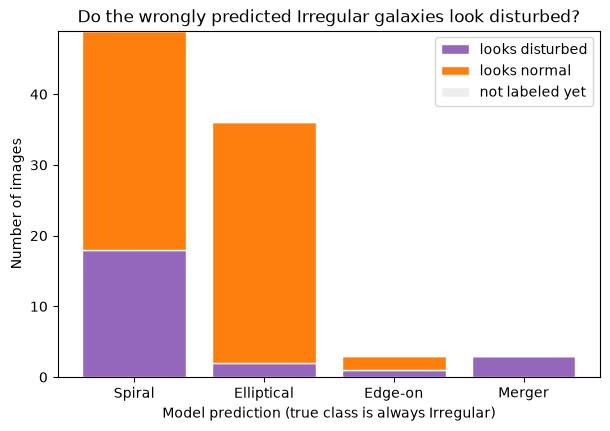

In [ ]:
VERDICTS = ['looks disturbed', 'looks normal', 'not labeled yet']
VERDICT_COLORS = ['#9467bd', '#ff7f0e', '#eeeeee']
predicted_classes = []
for class_name in CLASS_NAMES:
    if class_name in list(label_table['predicted_class']):
        predicted_classes.append(class_name)
figure, axis = plt.subplots(figsize=(7, 4.5))
bottoms = [0] * len(predicted_classes)

for verdict_number in range(len(VERDICTS)):
    verdict = VERDICTS[verdict_number]
    counts = []
    for class_name in predicted_classes:
        rows = label_table[(label_table['predicted_class'] == class_name) & (label_table['verdict'] == verdict)]
        counts.append(len(rows))
    axis.bar(predicted_classes, counts, bottom=bottoms, color=VERDICT_COLORS[verdict_number],
             edgecolor='white', label=verdict)
    for class_number in range(len(predicted_classes)):
        bottoms[class_number] = bottoms[class_number] + counts[class_number]

axis.set_xlabel('Model prediction (true class is always Irregular)')
axis.set_ylabel('Number of images')
axis.set_title('Do the wrongly predicted Irregular galaxies look disturbed?')
axis.legend()
plt.savefig('figures/fig6_irregular_labels.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.2 Colour or distance?
When the model gets an Irregular galaxy wrong and calls it “Elliptical”, is that because the galaxy is far away or because it is red?
Far away galaxies look redder (that is what redshift means), so redness and distance are linked.
We split the Irregular images at the median distance and the median redness into 4 groups: near or far, blue or red.
For every group we count how often the model is right and how often it predicts Spiral or Elliptical.

In [ ]:
irregular_rows = table[(table['true_class'] == 'Irregular') & (table['redshift'] > 0)]
median_redshift = irregular_rows['redshift'].median()
median_redness = irregular_rows['redness'].median()
group_rows = []

for distance in ['near', 'far']:
    for colour in ['blue', 'red']:
        if distance == 'near':
            rows = irregular_rows[irregular_rows['redshift'] <= median_redshift]
        else:
            rows = irregular_rows[irregular_rows['redshift'] > median_redshift]
        if colour == 'blue':
            rows = rows[rows['redness'] <= median_redness]
        else:
            rows = rows[rows['redness'] > median_redness]

        group_rows.append({
            'distance': distance,
            'colour': colour,
            'images': len(rows),
            'accuracy %': rows['correct'].mean() * 100,
            'predicted Spiral %': (rows['predicted_class'] == 'Spiral').mean() * 100,
            'predicted Elliptical %': (rows['predicted_class'] == 'Elliptical').mean() * 100,
        })

group_table = pd.DataFrame(group_rows)

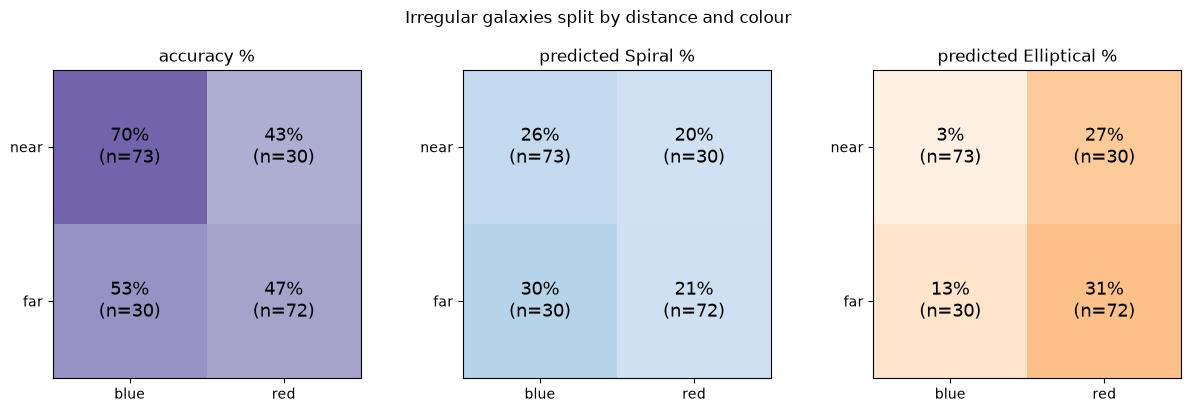

In [ ]:
values_to_show = ['accuracy %', 'predicted Spiral %', 'predicted Elliptical %']
color_maps = ['Purples', 'Blues', 'Oranges']
figure, axes = plt.subplots(1, 3, figsize=(15, 4))

for plot_number in range(3):
    axis = axes[plot_number]
    value_name = values_to_show[plot_number]
    grid = np.zeros((2, 2))
    image_counts = np.zeros((2, 2), dtype=int)
    for row_number in range(len(group_table)):
        if group_table['distance'][row_number] == 'near':
            grid_row = 0
        else:
            grid_row = 1
        if group_table['colour'][row_number] == 'blue':
            grid_column = 0
        else:
            grid_column = 1
        grid[grid_row, grid_column] = group_table[value_name][row_number]
        image_counts[grid_row, grid_column] = group_table['images'][row_number]

    axis.imshow(grid, cmap=color_maps[plot_number], vmin=0, vmax=100)
    for grid_row in range(2):
        for grid_column in range(2):
            text = f'{grid[grid_row, grid_column]:.0f}%\n(n={image_counts[grid_row, grid_column]})'
            axis.text(grid_column, grid_row, text, ha='center', va='center', fontsize=13)

    axis.set_xticks([0, 1], ['blue', 'red'])
    axis.set_yticks([0, 1], ['near', 'far'])
    axis.set_title(value_name)

figure.suptitle('Irregular galaxies split by distance and colour', y=1.03)
plt.savefig('figures/fig8_irregular_distance_and_colour_groups.png', dpi=150, bbox_inches='tight')
plt.show()